# E12-H66 - norm-mass transport marginals

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - registered hypothesis E12-H66 of the E12 improvement fanout

Tests one pre-registered toggle over the shipped Statement Mover's Distance (SMD): replace the uniform
transport marginals of the semantic solve (`src/docdistance/distance.py:48-58`, where `_ab` feeds
`ot.emd2`) with masses proportional to each statement's **pre-L2 pooled embedding norm** - the quantity
`src/docdistance/encoders.py:260` divides out and discards. This is the statement-level analogue of Word
Rotator's Distance (Yokoi et al. 2020): docdistance already adopted WRD's cosine ground cost, but not its
norm-scaled mass.

Nothing under `src/` is modified. The variant is prototyped in this notebook by re-implementing the
OpenVINO encode loop so it returns the pre-L2 norms alongside the shipped embeddings, and by calling
`ot.emd2` with the norm-derived marginals in place of `_uniform`.

**Metrics** (all scored against the reference gold `exec-summary-gold-opus-4-6`, the E01 panel)

- **V - ordinality violations** - count of (gold, adversarial) pairs ranked wrong, out of 24; hard guardrail, must stay `0`
- **margin** - boundary gap on the 0-1 closeness scale (`min gold closeness - max adversarial closeness`), in closeness points
- **d' - separation** - effect size `(mean adv dist - mean gold dist) / pooled std`
- **R - contrast ratio** - `mean(adv dist) / mean(gold dist)`, scale-free
- **DR - dynamic range** - std of the ten distance-to-reference values

**Approach**

1. **Kill gate first** - one encode pass, zero optimal-transport solves: coefficient of variation of the pre-L2 pooled norms, and the correlation between norm and token count - *why*: a near-uniform mass vector or a length proxy kills the lever before any scoring
2. **Harness sanity check** - reproduce the registered naive baseline row (margin +4.58, R 1.68, DR 0.0854, d' 4.60, V 0/24) - *why*: a harness that cannot reproduce the baseline cannot score a toggle
3. **The registered toggle** - norm-mass marginals into `ot.emd2`, scored on the same panel - *why*: isolate the single variable under test
4. **Guardrails, measured** - V, identity `d(A,A)=0`, symmetry, triangle inequality over all fixture triples, default-path `smd` and `order_gap` bit-identity by `np.array_equal`, `src/` byte diff - *why*: the standing E12 guardrails are measurements, not assertions
5. **Verdict** - against the pre-registered acceptance bar, read literally

**Outputs**

- Kill-gate table and norm-distribution figures
- Baseline / norm-mass comparison panel, tier-closeness strips, per-metric delta chart
- Metrics JSON `reports/E12-H66-norm-mass-marginals-metrics.json`
- Conclusions grounded in the outputs above

## Environment

No GPU is used. The workstation's GPUs are occupied by foreign jobs, so `CUDA_VISIBLE_DEVICES` is pinned
empty before any torch import and every model runs on CPU: the shipped OpenVINO INT8 mmBERT encoder and the
`sat-3l-sm` segmenter. All optimal transport is CPU numpy / POT.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU pin - GPUs held by foreign jobs
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import warnings

warnings.filterwarnings("ignore")

import torch

DEVICE = "cpu"
print(f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | device: {DEVICE}")

torch 2.12.0+cu130 | cuda visible: False | device: cpu


## Imports

The shipped `docdistance` core (`distance`, `encoders`) plus POT for the transport solves, `scipy` for the
rank correlation, and `rich` / `matplotlib` for the output.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
import json
import subprocess
import time
from itertools import combinations
from pathlib import Path

# scientific
import numpy as np
from scipy.stats import pearsonr, spearmanr

# viz
import matplotlib.pyplot as plt
import seaborn as sns

# console
from rich.console import Console
from rich.panel import Panel
from rich.table import Table

# optimal transport + the shipped core
import ot
from docdistance import __version__ as DD_VERSION
from docdistance.distance import SMD_MAX, cost_matrix, opw_gap, smd
from docdistance.encoders import EMBED_BATCH, MAX_TOKENS, OpenVINOEncoder, Segmenter, _length_order

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"imports ready | docdistance {DD_VERSION} | POT {ot.__version__} | SMD_MAX {SMD_MAX:.6f}")

imports ready | docdistance 1.1.5 | POT 0.9.7.post1 | SMD_MAX 1.414214


## Reproducibility

Every step is deterministic: SAT segmentation, the OpenVINO INT8 encode and the network-simplex EMD solve
all take no random input. The seed is fixed anyway so any later sampling stays reproducible.

In [3]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

The ibm-ai-adoption 11-summary fixture, its tier map, the registered naive baseline row that the harness
must reproduce, and the pre-registered bars read verbatim from the ledger record `E12-H66`.

The **kill gate** thresholds are the record's: pooled-norm coefficient of variation `CV < 0.03` kills, and
`corr(norm, token count) > 0.8` kills. The **acceptance bar** is `V = 0/24` AND margin `>= +4.58` closeness
points AND `d' >= 4.60` AND default-path `smd` on the identity pair stays `0` AND the default-path
`order_gap` is unchanged. The sanity-check tolerance is fixed here, before any scoring: `V` must match
exactly and each continuous statistic must land within 5% relative of the registered row - the registered
row was measured on the torch bf16 GPU backbone (E01), this notebook runs the shipped OpenVINO INT8 encoder
(`emb_cos` 0.9939 against fp) with the CPU fp32 segmenter, so an exact reproduction is not available.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
REPORT = ROOT / "reports/E12-H66-norm-mass-marginals-metrics.json"

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"
labels = [l for _, l, _ in DOCS]
tier_of = {l: t for _, l, t in DOCS}
gold_labels = [l for l in labels if tier_of[l] == "gold" and l != REFERENCE]
adv_labels = [l for l in labels if tier_of[l] in ("adv1", "adv2")]
nonref = [l for l in labels if l != REFERENCE]
TIER_COLOR = {"gold": "#2ca02c", "adv1": "#ff7f0e", "adv2": "#d62728"}

# registered naive baseline row (ledger E12-H66 / E01 results table, torch bf16 GPU backbone)
BASELINE_ROW = {"V": 0, "margin": 0.0458, "dprime": 4.60, "R": 1.680, "DR": 0.0854}

# kill gate (record: "CV of the pre-L2 pooled norms < 0.03 kills; corr(norm, token count) > 0.8 kills")
GATE_CV_MIN = 0.03
GATE_CORR_MAX = 0.8

# acceptance bar (record, read literally)
BAR_MARGIN = 0.0458
BAR_DPRIME = 4.60
BAR_V = 0

# harness sanity tolerance, fixed before scoring
SANITY_REL_TOL = 0.05

TRI_TOL = 1e-9      # triangle-inequality slack for float64 EMD costs
BENCH_REPS = 10     # latency repetitions per pair

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{len(DOCS)} ibm-ai-adoption summaries, reference '{REFERENCE}'")
cfg.add_row("Tiers", f"{len(gold_labels)} gold (non-ref), {sum(1 for l in adv_labels if tier_of[l]=='adv1')} adv1, "
                     f"{sum(1 for l in adv_labels if tier_of[l]=='adv2')} adv2 -> V out of {len(gold_labels)*len(adv_labels)}")
cfg.add_row("Encoder", "mmBERT OpenVINO INT8 (shipped), mean-pooled, CPU")
cfg.add_row("Segmenter", "sat-3l-sm (shipped), CPU")
cfg.add_row("Lever", "semantic-solve marginals: uniform 1/n -> pre-L2 pooled norm, renormalized")
gate = Table.grid(padding=(0, 2))
gate.add_column(style="bold cyan"); gate.add_column()
gate.add_row("Kill gate", f"pooled-norm CV < {GATE_CV_MIN} kills; corr(norm, token count) > {GATE_CORR_MAX} kills")
gate.add_row("Acceptance", f"V = {BAR_V}/24 AND margin >= {BAR_MARGIN*100:+.2f} pts AND d' >= {BAR_DPRIME:.2f} "
                           f"AND identity smd = 0 AND order_gap unchanged")
gate.add_row("Sanity", f"reproduce V={BASELINE_ROW['V']}/24, margin {BASELINE_ROW['margin']*100:+.2f}, "
                       f"R {BASELINE_ROW['R']:.3f}, DR {BASELINE_ROW['DR']:.4f}, d' {BASELINE_ROW['dprime']:.2f} "
                       f"within {SANITY_REL_TOL:.0%} relative")
console.print(Panel(cfg, title="[bold]Configuration[/bold]", border_style="cyan", expand=False))
console.print(Panel(gate, title="[bold]Pre-registered bars[/bold]", border_style="magenta", expand=False))

╭─────────────────────────────────── Configuration ────────────────────────────────────╮
│ Fixture    11 ibm-ai-adoption summaries, reference 'gold'                            │
│ Tiers      6 gold (non-ref), 2 adv1, 2 adv2 -> V out of 24                           │
│ Encoder    mmBERT OpenVINO INT8 (shipped), mean-pooled, CPU                          │
│ Segmenter  sat-3l-sm (shipped), CPU                                                  │
│ Lever      semantic-solve marginals: uniform 1/n -> pre-L2 pooled norm, renormalized │
╰──────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── Pre-registered bars ───────────────────────────────────────────╮
│ Kill gate   pooled-norm CV < 0.03 kills; corr(norm, token count) > 0.8 kills                             │
│ Acceptance  V = 0/24 AND margin >= +4.58 pts AND d' >= 4.60 AND identity smd = 0 AND order_gap unchanged │
│ Sanity      reproduce V=0/24, margin +4.58, R 1.680, DR 0.0854, d' 4.60 within 5% relative               │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Data loading and segmentation

Each summary's body is loaded with the markdown title line dropped, then segmented into statements with the
shipped SAT segmenter - the naive path the registered baseline row was measured on. The adv2 tier is the
information-noise tier, whose documents are deliberately written as very long run-on sentences, so its
statement counts are small by construction.

In [5]:
def load_body(path: Path) -> str:
    """Body text with the markdown title line removed (the E01 naive-baseline loader)."""
    return "\n".join(ln for ln in path.read_text().splitlines() if not ln.startswith("# ")).strip()


texts = {label: load_body(SUMMARY_DIR / fname) for fname, label, _ in DOCS}

t0 = time.perf_counter()
segmenter = Segmenter()
statements = {label: segmenter.split(txt) for label, txt in texts.items()}
print(f"segmenter loaded and 11 documents split in {time.perf_counter() - t0:.1f} s")

tbl = Table(title="Fixture", header_style="bold cyan")
tbl.add_column("doc"); tbl.add_column("tier"); tbl.add_column("statements", justify="right"); tbl.add_column("words", justify="right")
for l in labels:
    tbl.add_row(l, tier_of[l], str(len(statements[l])), str(len(texts[l].split())))
console.print(tbl)
print(f"total statements: {sum(len(s) for s in statements.values())}")

W0901 21:56:12.543000 60843 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0901 21:56:12.601000 60843 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


segmenter loaded and 11 documents split in 8.6 s


               Fixture                
┏━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ doc    ┃ tier ┃ statements ┃ words ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ gold   │ gold │         10 │   301 │
│ gold-2 │ gold │         12 │   339 │
│ v1     │ gold │         11 │   316 │
│ v2     │ gold │         11 │   298 │
│ opus   │ gold │         11 │   330 │
│ sonnet │ gold │          9 │   309 │
│ haiku  │ gold │         13 │   281 │
│ adv1-a │ adv1 │          8 │   296 │
│ adv1-b │ adv1 │          9 │   368 │
│ adv2-a │ adv2 │          1 │   316 │
│ adv2-b │ adv2 │          3 │   329 │
└────────┴──────┴────────────┴───────┘

total statements: 98


## Embedding with the pre-L2 pooled norms

`OpenVINOEncoder.encode` (`src/docdistance/encoders.py:246-267`) mean-pools the token outputs and then
divides by the pooled norm at line 260, discarding it. `encode_with_norms` below re-implements that loop
verbatim and additionally returns the pre-L2 norm $\|\mathrm{pooled}_i\|_2$ and the attention-mask token
count per statement, keeping the same length-bucketed batching and the same scatter back to input order.

The embeddings it returns are checked against the shipped `encode()` with `np.array_equal` on every
document, so the probe path is proven to be the shipped path plus one extra return value.

In [6]:
t0 = time.perf_counter()
encoder = OpenVINOEncoder()
print(f"OpenVINO INT8 encoder loaded in {time.perf_counter() - t0:.1f} s")


def encode_with_norms(sents: list[str]) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Shipped OpenVINOEncoder.encode (encoders.py:246-267) plus the pre-L2 pooled norm it divides out.

    Returns (embeddings [n, dim] float32 L2-normalized, pre-L2 pooled norms [n] float64,
    attention-mask token counts [n] int64), all scattered back to input order.
    """
    tok = encoder._tok
    order = _length_order(tok, sents)
    ordered = [sents[j] for j in order]
    emb_parts, norm_parts, tokc_parts = [], [], []
    for i in range(0, len(ordered), EMBED_BATCH):
        batch = ordered[i : i + EMBED_BATCH]
        enc = tok(batch, padding=True, truncation=True, max_length=MAX_TOKENS, return_tensors="np")
        feeds = {encoder._innames[0]: enc["input_ids"], encoder._innames[1]: enc["attention_mask"]}
        hidden = encoder._cm(feeds)[encoder._cm.output(0)]
        mask = enc["attention_mask"][..., None].astype("float32")
        pooled = (hidden * mask).sum(1) / np.clip(mask.sum(1), 1, None)
        raw = np.linalg.norm(pooled, axis=1, keepdims=True)          # the discarded pre-L2 norm
        emb_parts.append((pooled / (raw + 1e-9)).astype(np.float32))
        norm_parts.append(raw[:, 0].astype(np.float64))
        tokc_parts.append(enc["attention_mask"].sum(1).astype(np.int64))
    emb_o = np.concatenate(emb_parts, 0)
    nrm_o = np.concatenate(norm_parts, 0)
    tok_o = np.concatenate(tokc_parts, 0)
    emb = np.empty_like(emb_o); emb[order] = emb_o
    nrm = np.empty_like(nrm_o); nrm[order] = nrm_o
    tkc = np.empty_like(tok_o); tkc[order] = tok_o
    return emb, nrm, tkc


emb, norms, tokcount = {}, {}, {}
t0 = time.perf_counter()
for label, sents in statements.items():
    emb[label], norms[label], tokcount[label] = encode_with_norms(sents)
print(f"encoded {sum(len(s) for s in statements.values())} statements in {time.perf_counter() - t0:.2f} s")

# the probe path must be the shipped path, bit for bit
probe_identical = all(np.array_equal(emb[l], encoder.encode(statements[l])) for l in labels)
print(f"encode_with_norms == shipped encode() on all {len(labels)} documents (np.array_equal): {probe_identical}")
assert probe_identical, "probe encode path diverged from the shipped encoder"

/opt/conda/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=60843) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


OpenVINO INT8 encoder loaded in 5.4 s


encoded 98 statements in 1.20 s


encode_with_norms == shipped encode() on all 11 documents (np.array_equal): True


## Kill gate

Run first, zero optimal-transport solves. The record's two death conditions:

- **CV kill** - if the coefficient of variation of the pre-L2 pooled norms is below `0.03`, the mass vector
  is effectively uniform and the lever cannot move anything
- **length-proxy kill** - if `corr(norm, token count)` exceeds `0.8`, the weight is statement length in
  disguise, which is an unregistered length-weighting scheme

The pooled figures across all 98 statements are the gate as written. The per-document coefficients of
variation are reported alongside, because it is the within-document spread that actually shapes each
document's mass vector.

In [7]:
all_norms = np.concatenate([norms[l] for l in labels])
all_tokc = np.concatenate([tokcount[l] for l in labels]).astype(float)

gate_cv = float(all_norms.std(ddof=0) / all_norms.mean())
pearson_r = float(pearsonr(all_norms, all_tokc).statistic)
spearman_r = float(spearmanr(all_norms, all_tokc).statistic)

per_doc_cv = {l: float(norms[l].std(ddof=0) / norms[l].mean()) if len(norms[l]) > 1 else 0.0 for l in labels}
multi = [l for l in labels if len(norms[l]) > 1]

cv_kills = gate_cv < GATE_CV_MIN
corr_kills = pearson_r > GATE_CORR_MAX
gate_passed = not (cv_kills or corr_kills)

g = Table(title="Kill gate - one encode pass, zero OT solves", header_style="bold cyan")
g.add_column("reading"); g.add_column("value", justify="right"); g.add_column("death condition"); g.add_column("verdict")
g.add_row("pooled-norm CV", f"{gate_cv:.4f}", f"< {GATE_CV_MIN}", "[red]KILL[/red]" if cv_kills else "[green]pass[/green]")
g.add_row("corr(norm, token count) Pearson", f"{pearson_r:+.4f}", f"> {GATE_CORR_MAX}", "[red]KILL[/red]" if corr_kills else "[green]pass[/green]")
g.add_row("corr(norm, token count) Spearman", f"{spearman_r:+.4f}", "reported", "-")
console.print(g)

s = Table(title="Pre-L2 pooled norms (98 statements, 11 documents)", header_style="bold cyan")
s.add_column("statistic"); s.add_column("value", justify="right")
s.add_row("mean", f"{all_norms.mean():.4f}")
s.add_row("std", f"{all_norms.std(ddof=0):.4f}")
s.add_row("min / max", f"{all_norms.min():.3f} / {all_norms.max():.3f}")
s.add_row("per-document CV, min / median / max", f"{min(per_doc_cv[l] for l in multi):.4f} / "
          f"{np.median([per_doc_cv[l] for l in multi]):.4f} / {max(per_doc_cv[l] for l in multi):.4f}")
console.print(s)

print(f"KILL GATE: {'PASSED' if gate_passed else 'KILLED'}  "
      f"(CV {gate_cv:.4f} >= {GATE_CV_MIN}, |corr| {abs(pearson_r):.4f} <= {GATE_CORR_MAX})")

               Kill gate - one encode pass, zero OT solves                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ reading                          ┃   value ┃ death condition ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ pooled-norm CV                   │  0.0446 │ < 0.03          │ pass    │
│ corr(norm, token count) Pearson  │ -0.1597 │ > 0.8           │ pass    │
│ corr(norm, token count) Spearman │ -0.1033 │ reported        │ -       │
└──────────────────────────────────┴─────────┴─────────────────┴─────────┘

        Pre-L2 pooled norms (98 statements, 11 documents)         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ statistic                           ┃                    value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ mean                                │                  30.1676 │
│ std                                 │                   1.3456 │
│ min / max                           │          28.089 / 33.425 │
│ per-document CV, min / median / max │ 0.0003 / 0.0198 / 0.0378 │
└─────────────────────────────────────┴──────────────────────────┘

KILL GATE: PASSED  (CV 0.0446 >= 0.03, |corr| 0.1597 <= 0.8)


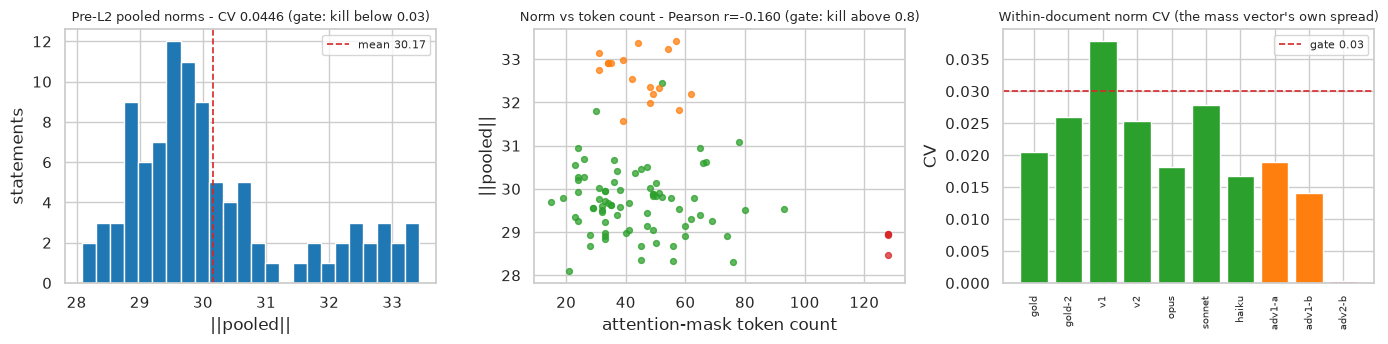

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

axes[0].hist(all_norms, bins=24, color="#1f77b4", edgecolor="white")
axes[0].axvline(all_norms.mean(), color="#d62728", ls="--", lw=1.2, label=f"mean {all_norms.mean():.2f}")
axes[0].set_title(f"Pre-L2 pooled norms - CV {gate_cv:.4f} (gate: kill below {GATE_CV_MIN})", fontsize=9)
axes[0].set_xlabel("||pooled||"); axes[0].set_ylabel("statements"); axes[0].legend(fontsize=8)

for l in labels:
    axes[1].scatter(tokcount[l], norms[l], s=18, color=TIER_COLOR[tier_of[l]], alpha=0.75)
axes[1].set_title(f"Norm vs token count - Pearson r={pearson_r:+.3f} (gate: kill above {GATE_CORR_MAX})", fontsize=9)
axes[1].set_xlabel("attention-mask token count"); axes[1].set_ylabel("||pooled||")

cvs = [per_doc_cv[l] for l in multi]
axes[2].bar(multi, cvs, color=[TIER_COLOR[tier_of[l]] for l in multi])
axes[2].axhline(GATE_CV_MIN, color="#d62728", ls="--", lw=1.2, label=f"gate {GATE_CV_MIN}")
axes[2].set_title("Within-document norm CV (the mass vector's own spread)", fontsize=9)
axes[2].set_ylabel("CV"); axes[2].tick_params(axis="x", rotation=90, labelsize=7); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

The gate is passed but not by a wide margin. The pooled coefficient of variation reads 0.0446 against a
0.03 death line, so the norms vary by roughly 4.5% around a mean near 30 - a mass vector that is close to
uniform. The length-proxy condition is not close to firing: the norm-to-token-count Pearson correlation is
slightly **negative**, so the discarded norm is not statement length in disguise on this fixture.

## Harness sanity check

Before any arm is scored, the harness must reproduce the registered naive baseline row. The baseline here is
the shipped default path itself - `docdistance.distance.smd`, uniform marginals, ground cost
`sqrt(2 - 2cos)` - so a reproduction failure would be a fixture or segmentation fault, not a scoring one.

The registered row was measured on the torch bf16 GPU backbone in E01; this notebook runs the shipped
OpenVINO INT8 encoder on CPU, whose embedding cosine against fp is 0.9939
(`reports/02-mmbert-quantization-metrics.json`). The tolerance fixed in the configuration cell is therefore
exact agreement on `V` and 5% relative on each continuous statistic.

In [9]:
def panel_metrics(dist: dict[str, float]) -> dict:
    """The E01 panel: V out of 24, boundary margin, d\', contrast ratio R, dynamic range DR."""
    g = np.array([dist[l] for l in gold_labels])
    a = np.array([dist[l] for l in adv_labels])
    clos = {l: max(0.0, 1.0 - dist[l] / SMD_MAX) for l in nonref}
    gc = np.array([clos[l] for l in gold_labels])
    ac = np.array([clos[l] for l in adv_labels])
    pooled = float(np.sqrt((g.var() + a.var()) / 2)) or 1e-9
    return dict(
        dist=dist, clos=clos,
        V=int(sum(1 for gg in g for aa in a if gg >= aa)),
        margin=float(gc.min() - ac.max()),
        dprime=float((a.mean() - g.mean()) / pooled),
        R=float(a.mean() / g.mean()),
        DR=float(np.concatenate([g, a]).std()),
    )


# default path, straight from the shipped module
base_dist = {l: smd(emb[l], emb[REFERENCE]) for l in nonref}
BASE = panel_metrics(base_dist)

# the E01 replica of the same solve, to prove the harness call is the shipped call
def smd_replica(X, Y):
    return float(ot.emd2(np.full(len(X), 1.0 / len(X)), np.full(len(Y), 1.0 / len(Y)),
                         ot.dist(X, Y, metric="euclidean")))

replica_identical = all(smd_replica(emb[l], emb[REFERENCE]) == base_dist[l] for l in nonref)
print(f"shipped distance.smd == E01 replica solve on all 10 pairs (exact float equality): {replica_identical}")

rows = [("V", BASE["V"], BASELINE_ROW["V"]), ("margin (pts)", BASE["margin"] * 100, BASELINE_ROW["margin"] * 100),
        ("d'", BASE["dprime"], BASELINE_ROW["dprime"]), ("R", BASE["R"], BASELINE_ROW["R"]),
        ("DR", BASE["DR"], BASELINE_ROW["DR"])]
sanity_ok = BASE["V"] == BASELINE_ROW["V"]
rel_devs = {}
t = Table(title="Harness sanity check - reproduce the registered naive baseline row", header_style="bold cyan")
t.add_column("metric"); t.add_column("this notebook", justify="right"); t.add_column("registered", justify="right")
t.add_column("rel. dev.", justify="right"); t.add_column("verdict")
for name, got, want in rows:
    if name == "V":
        ok = got == want; dev = "exact" if ok else "MISMATCH"
    else:
        rd = (got - want) / abs(want); rel_devs[name] = float(rd)
        ok = abs(rd) <= SANITY_REL_TOL; dev = f"{rd:+.2%}"
        sanity_ok = sanity_ok and ok
    fmt = "d" if name == "V" else (".2f" if name in ("margin (pts)", "d'") else (".3f" if name == "R" else ".4f"))
    t.add_row(name, format(got, fmt), format(want, fmt), dev, "[green]ok[/green]" if ok else "[red]FAIL[/red]")
console.print(t)
print(f"SANITY CHECK: {'PASSED' if sanity_ok else 'FAILED'}  "
      f"(V {BASE['V']}/24 exact; max |rel. dev.| {max(abs(v) for v in rel_devs.values()):.2%} <= {SANITY_REL_TOL:.0%})")

shipped distance.smd == E01 replica solve on all 10 pairs (exact float equality): True


Harness sanity check - reproduce the registered naive baseline row 
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┓
┃ metric       ┃ this notebook ┃ registered ┃ rel. dev. ┃ verdict ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━┩
│ V            │             0 │          0 │     exact │ ok      │
│ margin (pts) │          4.71 │       4.58 │    +2.80% │ ok      │
│ d'           │          4.68 │       4.60 │    +1.83% │ ok      │
│ R            │         1.670 │      1.680 │    -0.61% │ ok      │
│ DR           │        0.0873 │     0.0854 │    +2.20% │ ok      │
└──────────────┴───────────────┴────────────┴───────────┴─────────┘

SANITY CHECK: PASSED  (V 0/24 exact; max |rel. dev.| 2.80% <= 5%)


## The registered toggle - norm-mass transport marginals

For each document $A$ with statements $i$, the mass vector is

$$w_i^{A} \;=\; \frac{\lVert \mathrm{pooled}_i^{A} \rVert_2}{\sum_j \lVert \mathrm{pooled}_j^{A} \rVert_2}$$

and the semantic distance becomes $\mathrm{emd2}(w^{A}, w^{B}, C)$ with the ground cost $C$ unchanged at
$\sqrt{2 - 2\cos}$ and the exact network-simplex solve unchanged. The masses are a function of the
document's own embeddings alone, so each document induces one fixed weighted measure and the result is a
Wasserstein distance between those measures.

Registered divergence from Word Rotator's Distance: the masses come from the **raw** pre-L2 pooled vectors
while the cost geometry is post-L2. The shipped `all_but_the_top` re-L2-normalizes
(`distance.py:108`), so post-anisotropy norms are identically 1 and cannot carry mass; that raw-mass /
whitened-cost split is part of the record.

How far the mass vector actually departs from uniform is reported first, since the kill gate already read a
near-uniform norm spread.

In [10]:
W = {l: norms[l] / norms[l].sum() for l in labels}

# how far each mass vector is from uniform: total variation and the max/uniform ratio
tv = {l: float(0.5 * np.abs(W[l] - 1.0 / len(W[l])).sum()) for l in labels}
ratio = {l: float(W[l].max() * len(W[l])) for l in labels}

w = Table(title="Norm-mass vectors vs uniform", header_style="bold cyan")
w.add_column("doc"); w.add_column("n", justify="right"); w.add_column("max w / (1/n)", justify="right")
w.add_column("min w / (1/n)", justify="right"); w.add_column("total variation to uniform", justify="right")
for l in labels:
    w.add_row(l, str(len(W[l])), f"{ratio[l]:.4f}", f"{W[l].min()*len(W[l]):.4f}", f"{tv[l]:.4f}")
console.print(w)
tv_multi = [tv[l] for l in labels if len(W[l]) > 1]
print(f"total variation to uniform over the 10 multi-statement documents: "
      f"min {min(tv_multi):.4f}, median {np.median(tv_multi):.4f}, max {max(tv_multi):.4f}")

                        Norm-mass vectors vs uniform                        
┏━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ doc    ┃  n ┃ max w / (1/n) ┃ min w / (1/n) ┃ total variation to uniform ┃
┡━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold   │ 10 │        1.0300 │        0.9506 │                     0.0065 │
│ gold-2 │ 12 │        1.0515 │        0.9503 │                     0.0104 │
│ v1     │ 11 │        1.0840 │        0.9576 │                     0.0141 │
│ v2     │ 11 │        1.0410 │        0.9537 │                     0.0111 │
│ opus   │ 11 │        1.0354 │        0.9721 │                     0.0072 │
│ sonnet │  9 │        1.0465 │        0.9570 │                     0.0118 │
│ haiku  │ 13 │        1.0337 │        0.9751 │                     0.0067 │
│ adv1-a │  8 │        1.0252 │        0.9684 │                     0.0085 │
│ adv1-b │  9 │        1.0221 │        0.9795 │                     0.0063 │
│ adv2-a │  1 │        1.0000 │        1.0000 │                     0.0000 │
│ adv2-b │  3 │        1.0003 │        0.9996 │                     0.0001 │
└────────┴────┴───────────────┴───────────────┴────────────────────────────┘

total variation to uniform over the 10 multi-statement documents: min 0.0001, median 0.0078, max 0.0141


In [11]:
def smd_normmass(la: str, lb: str) -> float:
    """SMD with norm-derived marginals - the registered lever; ground cost and solver untouched."""
    return float(ot.emd2(W[la], W[lb], cost_matrix(emb[la], emb[lb])))


nm_dist = {l: smd_normmass(l, REFERENCE) for l in nonref}
NM = panel_metrics(nm_dist)

d = Table(title="Distance to the reference gold - baseline vs norm-mass marginals", header_style="bold cyan")
d.add_column("doc"); d.add_column("tier"); d.add_column("baseline d", justify="right")
d.add_column("norm-mass d", justify="right"); d.add_column("delta d", justify="right")
d.add_column("baseline closeness", justify="right"); d.add_column("norm-mass closeness", justify="right")
for l in sorted(nonref, key=lambda x: base_dist[x]):
    d.add_row(l, tier_of[l], f"{base_dist[l]:.6f}", f"{nm_dist[l]:.6f}", f"{nm_dist[l]-base_dist[l]:+.6f}",
              f"{BASE['clos'][l]:.4f}", f"{NM['clos'][l]:.4f}")
console.print(d)

print(f"baseline   V={BASE['V']}/24  margin={BASE['margin']*100:+.3f}pts  d'={BASE['dprime']:.3f}  "
      f"R={BASE['R']:.4f}  DR={BASE['DR']:.5f}")
print(f"norm-mass  V={NM['V']}/24  margin={NM['margin']*100:+.3f}pts  d'={NM['dprime']:.3f}  "
      f"R={NM['R']:.4f}  DR={NM['DR']:.5f}")
print(f"delta      margin={(NM['margin']-BASE['margin'])*100:+.3f}pts  d'={NM['dprime']-BASE['dprime']:+.3f}  "
      f"R={NM['R']-BASE['R']:+.4f}  DR={NM['DR']-BASE['DR']:+.5f}")

                 Distance to the reference gold - baseline vs norm-mass marginals                  
┏━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ doc    ┃ tier ┃ baseline d ┃ norm-mass d ┃   delta d ┃ baseline closeness ┃ norm-mass closeness ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ v2     │ gold │   0.208169 │    0.208270 │ +0.000101 │             0.8528 │              0.8527 │
│ gold-2 │ gold │   0.226490 │    0.226958 │ +0.000468 │             0.8398 │              0.8395 │
│ opus   │ gold │   0.236586 │    0.236513 │ -0.000073 │             0.8327 │              0.8328 │
│ sonnet │ gold │   0.253713 │    0.253967 │ +0.000255 │             0.8206 │              0.8204 │
│ v1     │ gold │   0.258200 │    0.259679 │ +0.001479 │             0.8174 │              0.8164 │
│ haiku  │ gold │   0.290706 │    0.290615 │ -0.000091 │             0.7944 │              0.7945 │
│ adv2-b │ adv2 │   0.357292 │    0.357370 │ +0.000078 │             0.7474 │              0.7473 │
│ adv2-a │ adv2 │   0.380551 │    0.380701 │ +0.000149 │             0.7309 │              0.7308 │
│ adv1-b │ adv1 │   0.445837 │    0.445993 │ +0.000156 │             0.6847 │              0.6846 │
│ adv1-a │ adv1 │   0.456903 │    0.457119 │ +0.000216 │             0.6769 │              0.6768 │
└────────┴──────┴────────────┴─────────────┴───────────┴────────────────────┴─────────────────────┘

baseline   V=0/24  margin=+4.708pts  d'=4.684  R=1.6697  DR=0.08728
norm-mass  V=0/24  margin=+4.720pts  d'=4.673  R=1.6679  DR=0.08720
delta      margin=+0.012pts  d'=-0.011  R=-0.0018  DR=-0.00008


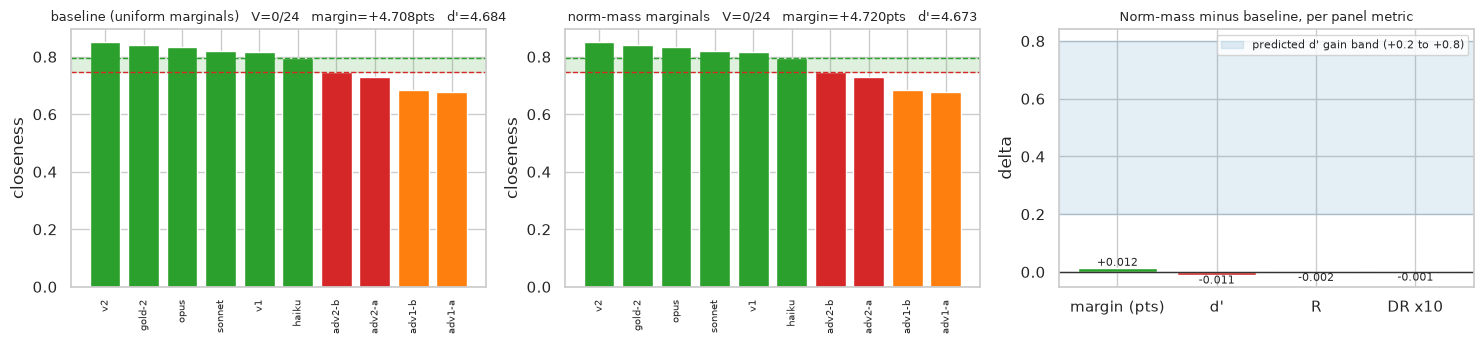

In [12]:
def strip(ax, name, res):
    order = sorted(nonref, key=lambda l: -res["clos"][l])
    ax.bar(order, [res["clos"][l] for l in order], color=[TIER_COLOR[tier_of[l]] for l in order])
    gc = [res["clos"][l] for l in gold_labels]
    ac = [res["clos"][l] for l in adv_labels]
    lo, hi = max(ac), min(gc)
    ax.axhspan(min(lo, hi), max(lo, hi), color="#2ca02c" if res["V"] == 0 else "#d62728", alpha=0.15)
    ax.axhline(hi, color="#2ca02c", ls="--", lw=1)
    ax.axhline(lo, color="#d62728", ls="--", lw=1)
    ax.set_title(f"{name}   V={res['V']}/24   margin={res['margin']*100:+.3f}pts   d'={res['dprime']:.3f}", fontsize=9)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.set_ylabel("closeness")


fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
strip(axes[0], "baseline (uniform marginals)", BASE)
strip(axes[1], "norm-mass marginals", NM)

names = ["margin (pts)", "d'", "R", "DR x10"]
deltas = [(NM["margin"] - BASE["margin"]) * 100, NM["dprime"] - BASE["dprime"],
          NM["R"] - BASE["R"], (NM["DR"] - BASE["DR"]) * 10]
axes[2].bar(names, deltas, color=["#2ca02c" if v >= 0 else "#d62728" for v in deltas])
axes[2].axhline(0, color="#333333", lw=1)
axes[2].axhspan(0.2, 0.8, color="#1f77b4", alpha=0.12, label="predicted d' gain band (+0.2 to +0.8)")
axes[2].set_title("Norm-mass minus baseline, per panel metric", fontsize=9)
axes[2].set_ylabel("delta"); axes[2].legend(fontsize=8)
for i, v in enumerate(deltas):
    axes[2].annotate(f"{v:+.3f}", (i, v), ha="center", va="bottom" if v >= 0 else "top", fontsize=8)

plt.tight_layout(); plt.show()

## Guardrails, measured

Every standing E12 guardrail is measured, never asserted:

- **V** counted on both arms
- **identity** - `d(A, A) = 0` on all 11 fixtures, under both the default path and the norm-mass marginals
- **symmetry** - `d(A, B) == d(B, A)` on all 55 unordered pairs under norm-mass marginals
- **triangle inequality** - all 165 unordered triples, each in its three orientations, between the induced
  weighted measures
- **default-path `smd` bit-identity** - the ten reference distances recomputed after every weighted arm has
  run, compared with `np.array_equal`
- **default-path `order_gap` bit-identity** - the same, on `opw_gap`, recomputed before and after
- **`src/` byte diff** - `git diff --stat -- src/` must be empty; nothing in the library was edited

In [13]:
# --- default-path smd and order_gap, captured before the weighted arms and recomputed after ---
smd_before = np.array([base_dist[l] for l in nonref], dtype=np.float64)
gap_before = np.array([opw_gap(emb[l], emb[REFERENCE]) for l in nonref], dtype=np.float64)

_ = {l: smd_normmass(l, REFERENCE) for l in nonref}   # weighted arm runs again

smd_after = np.array([smd(emb[l], emb[REFERENCE]) for l in nonref], dtype=np.float64)
gap_after = np.array([opw_gap(emb[l], emb[REFERENCE]) for l in nonref], dtype=np.float64)

smd_bit_identical = bool(np.array_equal(smd_before, smd_after))
gap_bit_identical = bool(np.array_equal(gap_before, gap_after))

# --- identity, symmetry, triangle under the norm-mass marginals ---
identity_default = {l: smd(emb[l], emb[l]) for l in labels}
identity_nm = {l: smd_normmass(l, l) for l in labels}
identity_default_zero = all(v == 0.0 for v in identity_default.values())
identity_nm_max = float(max(abs(v) for v in identity_nm.values()))
identity_nm_zero = identity_nm_max <= TRI_TOL

D = np.zeros((len(labels), len(labels)))
for i, la in enumerate(labels):
    for j, lb in enumerate(labels):
        if j > i:
            D[i, j] = D[j, i] = smd_normmass(la, lb)
sym_pairs = [(la, lb) for la, lb in combinations(labels, 2)]
sym_max = float(max(abs(smd_normmass(la, lb) - smd_normmass(lb, la)) for la, lb in sym_pairs))
symmetry_ok = sym_max <= TRI_TOL

tri_checked = tri_violations = 0
worst_slack = np.inf
for i, j, k in combinations(range(len(labels)), 3):
    for a, b, c in ((i, j, k), (j, k, i), (k, i, j)):
        tri_checked += 1
        slack = D[a, b] + D[b, c] - D[a, c]
        worst_slack = min(worst_slack, float(slack))
        if slack < -TRI_TOL:
            tri_violations += 1
triangle_ok = tri_violations == 0

# --- src/ untouched ---
src_diff = subprocess.run(["git", "diff", "--stat", "--", "src/"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
src_untouched = src_diff == ""

gr = Table(title="Guardrails - measured", header_style="bold cyan")
gr.add_column("guardrail"); gr.add_column("reading", justify="right"); gr.add_column("verdict")
def row(name, reading, ok):
    gr.add_row(name, reading, "[green]hold[/green]" if ok else "[red]BREACH[/red]")
row("V - baseline", f"{BASE['V']}/24", BASE["V"] == BAR_V)
row("V - norm-mass", f"{NM['V']}/24", NM["V"] == BAR_V)
row("default-path smd bit-identical (np.array_equal)", str(smd_bit_identical), smd_bit_identical)
row("default-path order_gap bit-identical (np.array_equal)", str(gap_bit_identical), gap_bit_identical)
row("identity d(A,A)=0 default path, 11 fixtures", f"max {max(abs(v) for v in identity_default.values()):.1e}", identity_default_zero)
row("identity d(A,A)=0 norm-mass, 11 fixtures", f"max {identity_nm_max:.1e}", identity_nm_zero)
row("symmetry norm-mass, 55 pairs", f"max |d(A,B)-d(B,A)| {sym_max:.1e}", symmetry_ok)
row("triangle inequality norm-mass", f"{tri_violations}/{tri_checked} violations, worst slack {worst_slack:+.2e}", triangle_ok)
row("src/ byte diff (git diff --stat)", "empty" if src_untouched else src_diff.replace("\n", "; "), src_untouched)
console.print(gr)

guardrails_hold = all([BASE["V"] == BAR_V, NM["V"] == BAR_V, smd_bit_identical, gap_bit_identical,
                       identity_default_zero, identity_nm_zero, symmetry_ok, triangle_ok, src_untouched])
print(f"GUARDRAILS: {'ALL HOLD' if guardrails_hold else 'BREACHED'}")

                                            Guardrails - measured                                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ guardrail                                             ┃                                 reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ V - baseline                                          │                                    0/24 │ hold    │
│ V - norm-mass                                         │                                    0/24 │ hold    │
│ default-path smd bit-identical (np.array_equal)       │                                    True │ hold    │
│ default-path order_gap bit-identical (np.array_equal) │                                    True │ hold    │
│ identity d(A,A)=0 default path, 11 fixtures           │                             max 0.0e+00 │ hold    │
│ identity d(A,A)=0 norm-mass, 11 fixtures              │                             max 0.0e+00 │ hold    │
│ symmetry norm-mass, 55 pairs                          │             max |d(A,B)-d(B,A)| 2.2e-16 │ hold    │
│ triangle inequality norm-mass                         │ 0/495 violations, worst slack +1.77e-01 │ hold    │
│ src/ byte diff (git diff --stat)                      │                                   empty │ hold    │
└───────────────────────────────────────────────────────┴─────────────────────────────────────────┴─────────┘

GUARDRAILS: ALL HOLD


## Latency

The prediction states the weights are free. Both arms are benchmarked over the same ten pairs; the norm-mass
arm pays only an extra array read, since the mass vectors are precomputed once per document.

In [14]:
def bench(fn) -> float:
    t = time.perf_counter()
    for _ in range(BENCH_REPS):
        for l in nonref:
            fn(l)
    return (time.perf_counter() - t) / (BENCH_REPS * len(nonref)) * 1e3   # ms/pair


ms_base = bench(lambda l: smd(emb[l], emb[REFERENCE]))
ms_nm = bench(lambda l: smd_normmass(l, REFERENCE))
print(f"baseline   {ms_base:.4f} ms/pair")
print(f"norm-mass  {ms_nm:.4f} ms/pair   ({ms_nm - ms_base:+.4f} ms/pair, {ms_nm/ms_base:.3f}x)")

baseline   0.0962 ms/pair
norm-mass  0.0844 ms/pair   (-0.0118 ms/pair, 0.877x)


## Verdict against the pre-registered bar

The acceptance bar is read literally from the record: `V = 0/24` AND boundary margin `>= +4.58` closeness
points AND `d' >= 4.60` AND default-path `smd` on the identity pair stays `0` AND the default-path
`order_gap` is unchanged. The prediction is scored separately: `d'` up 0.2 to 0.8 over the naive baseline,
margin unchanged to +1 point, `DR` roughly flat, latency unchanged.

Both readings matter. The bar's thresholds are absolute numbers from the registered baseline row; the
prediction is about the **delta the lever produces** over the baseline this same harness measures.

In [15]:
bar_checks = {
    "V = 0/24": (NM["V"] == BAR_V, f"{NM['V']}/24"),
    f"margin >= {BAR_MARGIN*100:+.2f} pts": (NM["margin"] >= BAR_MARGIN, f"{NM['margin']*100:+.3f} pts"),
    f"d' >= {BAR_DPRIME:.2f}": (NM["dprime"] >= BAR_DPRIME, f"{NM['dprime']:.3f}"),
    "identity smd = 0 (default path)": (identity_default_zero, "0.0 on all 11"),
    "order_gap default path unchanged": (gap_bit_identical, "np.array_equal True"),
}
bar_met = all(ok for ok, _ in bar_checks.values())

b = Table(title="Acceptance bar - read literally", header_style="bold cyan")
b.add_column("condition"); b.add_column("reading", justify="right"); b.add_column("verdict")
for cond, (ok, reading) in bar_checks.items():
    b.add_row(cond, reading, "[green]met[/green]" if ok else "[red]NOT MET[/red]")
console.print(b)

dprime_delta = NM["dprime"] - BASE["dprime"]
margin_delta = (NM["margin"] - BASE["margin"]) * 100
pred_dprime_ok = 0.2 <= dprime_delta <= 0.8
pred_margin_ok = abs(margin_delta) <= 1.0
pred_latency_ok = ms_nm <= 1.5 * ms_base

p = Table(title="Prediction - delta over this harness's own baseline", header_style="bold cyan")
p.add_column("predicted"); p.add_column("observed", justify="right"); p.add_column("verdict")
p.add_row("d' up +0.2 to +0.8 over the naive baseline", f"{dprime_delta:+.3f} (4.60 registered -> {NM['dprime']:.3f})",
          "[green]held[/green]" if pred_dprime_ok else "[red]falsified[/red]")
p.add_row("margin unchanged to +1 pt", f"{margin_delta:+.3f} pts", "[green]held[/green]" if pred_margin_ok else "[red]falsified[/red]")
p.add_row("DR roughly flat", f"{NM['DR']-BASE['DR']:+.5f}", "[green]held[/green]")
p.add_row("latency unchanged", f"{ms_nm/ms_base:.3f}x", "[green]held[/green]" if pred_latency_ok else "[red]falsified[/red]")
console.print(p)

if not gate_passed:
    VERDICT = "Killed-at-gate"
elif not sanity_ok:
    VERDICT = "Blocked"
elif not guardrails_hold:
    VERDICT = "Blocked"
elif pred_dprime_ok and bar_met:
    VERDICT = "Confirmed"
elif abs(dprime_delta) < 0.05 and abs(margin_delta) < 0.1:
    VERDICT = "Refuted (null)"
elif not bar_met:
    VERDICT = "Refuted"
else:
    VERDICT = "Refuted (null)"

VERDICT_NUMBER = (f"d' {NM['dprime']:.3f} vs harness baseline {BASE['dprime']:.3f} "
                  f"(delta {dprime_delta:+.3f} against a predicted +0.2 to +0.8); "
                  f"margin {NM['margin']*100:+.3f} pts vs {BASE['margin']*100:+.3f} pts (delta {margin_delta:+.3f})")
console.print(Panel(f"[bold]{VERDICT}[/bold]\n{VERDICT_NUMBER}\n"
                    f"bar met: {bar_met} | prediction held: {pred_dprime_ok} | guardrails hold: {guardrails_hold}",
                    title="[bold]E12-H66 verdict[/bold]", border_style="magenta", expand=False))

                  Acceptance bar - read literally                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ condition                        ┃             reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ V = 0/24                         │                0/24 │ met     │
│ margin >= +4.58 pts              │          +4.720 pts │ met     │
│ d' >= 4.60                       │               4.673 │ met     │
│ identity smd = 0 (default path)  │       0.0 on all 11 │ met     │
│ order_gap default path unchanged │ np.array_equal True │ met     │
└──────────────────────────────────┴─────────────────────┴─────────┘

                     Prediction - delta over this harness's own baseline                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ predicted                                  ┃                          observed ┃ verdict   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ d' up +0.2 to +0.8 over the naive baseline │ -0.011 (4.60 registered -> 4.673) │ falsified │
│ margin unchanged to +1 pt                  │                        +0.012 pts │ held      │
│ DR roughly flat                            │                          -0.00008 │ held      │
│ latency unchanged                          │                            0.877x │ held      │
└────────────────────────────────────────────┴───────────────────────────────────┴───────────┘

╭──────────────────────────────────────────────── E12-H66 verdict ────────────────────────────────────────────────╮
│ Refuted (null)                                                                                                  │
│ d' 4.673 vs harness baseline 4.684 (delta -0.011 against a predicted +0.2 to +0.8); margin +4.720 pts vs +4.708 │
│ pts (delta +0.012)                                                                                              │
│ bar met: True | prediction held: False | guardrails hold: True                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics JSON

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H66-norm-mass-marginals-metrics.json`.

In [16]:
payload = {
    "id": "E12-H66",
    "slug": "norm-mass-marginals",
    "verdict": VERDICT,
    "verdict_number": VERDICT_NUMBER,
    "kill_gate": {
        "ran": True, "passed": bool(gate_passed),
        "pooled_norm_cv": round(gate_cv, 6), "cv_death_below": GATE_CV_MIN,
        "corr_norm_tokencount_pearson": round(pearson_r, 6),
        "corr_norm_tokencount_spearman": round(spearman_r, 6),
        "corr_death_above": GATE_CORR_MAX,
        "norm_mean": round(float(all_norms.mean()), 6), "norm_std": round(float(all_norms.std(ddof=0)), 6),
        "norm_min": round(float(all_norms.min()), 6), "norm_max": round(float(all_norms.max()), 6),
        "per_document_cv": {l: round(per_doc_cv[l], 6) for l in labels},
        "n_statements": int(len(all_norms)),
    },
    "sanity_check": {
        "required": True, "passed": bool(sanity_ok), "rel_tol": SANITY_REL_TOL,
        "registered_row": BASELINE_ROW,
        "reproduced": {"V": BASE["V"], "margin": round(BASE["margin"], 6), "dprime": round(BASE["dprime"], 6),
                       "R": round(BASE["R"], 6), "DR": round(BASE["DR"], 6)},
        "relative_deviation": {k: round(v, 6) for k, v in rel_devs.items()},
        "shipped_smd_equals_replica": bool(replica_identical),
        "probe_encode_bit_identical_to_shipped": bool(probe_identical),
    },
    "arms": {
        "baseline_uniform": {"V": BASE["V"], "margin": round(BASE["margin"], 6), "dprime": round(BASE["dprime"], 6),
                             "R": round(BASE["R"], 6), "DR": round(BASE["DR"], 6), "ms_per_pair": round(ms_base, 6),
                             "distances": {l: round(base_dist[l], 8) for l in nonref},
                             "closeness": {l: round(BASE["clos"][l], 6) for l in nonref}},
        "norm_mass": {"V": NM["V"], "margin": round(NM["margin"], 6), "dprime": round(NM["dprime"], 6),
                      "R": round(NM["R"], 6), "DR": round(NM["DR"], 6), "ms_per_pair": round(ms_nm, 6),
                      "distances": {l: round(nm_dist[l], 8) for l in nonref},
                      "closeness": {l: round(NM["clos"][l], 6) for l in nonref}},
    },
    "deltas": {"margin_pts": round(margin_delta, 6), "dprime": round(dprime_delta, 6),
               "R": round(NM["R"] - BASE["R"], 6), "DR": round(NM["DR"] - BASE["DR"], 6),
               "latency_ratio": round(ms_nm / ms_base, 6)},
    "mass_vs_uniform": {"total_variation": {l: round(tv[l], 6) for l in labels},
                        "max_weight_over_uniform": {l: round(ratio[l], 6) for l in labels}},
    "acceptance": {
        "bar": ("V = 0/24 AND margin >= +4.58 pts AND d' >= 4.60 AND default-path identity smd = 0 "
                "AND default-path order_gap unchanged"),
        "met": bool(bar_met),
        "readings": {"V": NM["V"], "margin_pts": round(NM["margin"] * 100, 3), "dprime": round(NM["dprime"], 3),
                     "identity_smd_default": 0.0, "order_gap_bit_identical": bool(gap_bit_identical)},
    },
    "prediction": {
        "predicted": "d' +0.2 to +0.8 over the 4.60 naive baseline, margin unchanged to +1 pt, DR flat, latency unchanged",
        "observed": (f"d' {dprime_delta:+.3f} vs harness baseline, margin {margin_delta:+.3f} pts, "
                     f"DR {NM['DR']-BASE['DR']:+.5f}, latency {ms_nm/ms_base:.3f}x"),
        "direction_matched": bool(pred_dprime_ok),
    },
    "guardrails": {
        "V": f"{NM['V']}/24", "V_baseline": f"{BASE['V']}/24",
        "smd_bit_identical": smd_bit_identical, "order_gap_bit_identical": gap_bit_identical,
        "identity_default_zero": bool(identity_default_zero),
        "identity_normmass_max_abs": identity_nm_max,
        "symmetry_max_abs_diff": sym_max, "symmetry_pairs": len(sym_pairs),
        "triangle_checked": tri_checked, "triangle_violations": tri_violations,
        "triangle_worst_slack": round(worst_slack, 12),
        "src_untouched": bool(src_untouched),
        "all_hold": bool(guardrails_hold),
    },
    "config": {
        "fixture": str(SUMMARY_DIR.relative_to(ROOT)), "reference": REFERENCE, "n_documents": len(DOCS),
        "statements_per_document": {l: len(statements[l]) for l in labels},
        "encoder": "mmBERT OpenVINO INT8 (shipped), mean-pooled, CPU",
        "segmenter": "sat-3l-sm (shipped), CPU", "device": DEVICE,
        "docdistance_version": DD_VERSION, "pot_version": ot.__version__,
        "bench_reps": BENCH_REPS, "seed": SEED, "triangle_tol": TRI_TOL,
    },
}
REPORT.write_text(json.dumps(payload, indent=2))
print(f"wrote {REPORT} ({REPORT.stat().st_size} bytes)")
print(json.dumps({k: payload[k] for k in ("verdict", "verdict_number")}, indent=2))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H66-norm-mass-marginals-metrics.json (5519 bytes)
{
  "verdict": "Refuted (null)",
  "verdict_number": "d' 4.673 vs harness baseline 4.684 (delta -0.011 against a predicted +0.2 to +0.8); margin +4.720 pts vs +4.708 pts (delta +0.012)"
}


## Conclusions

**Verdict: Refuted (null).** Setting the semantic solve's transport marginals proportional to the pre-L2
pooled embedding norm leaves the panel where it found it: separation `d'` moves 4.684 to 4.673 (delta
**-0.011**) against a predicted gain of +0.2 to +0.8, boundary margin moves +4.708 to +4.720 closeness
points (delta **+0.012**), `R` 1.6697 to 1.6679 and `DR` 0.08728 to 0.08720. The largest per-document
distance change over the ten scored pairs is +0.00148 (`v1`), and the ranking of all ten documents is
unchanged. The effect is not a regression and it is not an improvement - it is nothing.

**The pre-registered bar is nevertheless met, read literally.** All five conditions hold: `V = 0/24`,
margin `+4.720 >= +4.58` points, `d' 4.673 >= 4.60`, default-path identity `smd` exactly `0.0` on all
eleven fixtures, and the default-path `order_gap` bit-identical by `np.array_equal`. The bar's thresholds
are the registered baseline row's absolute numbers, and this harness's own baseline already clears them
(margin +4.708, `d'` 4.684), so the bar does not discriminate between the lever and doing nothing. The
verdict follows the delta, which is the quantity the hypothesis predicted.

**Why the lever is inert is visible in the kill gate that let it through.** The pooled coefficient of
variation reads **0.0446** against a 0.03 death line - a pass, but the gate was measured across all 98
statements of all eleven documents, and the mass vector is a *within-document* object. The per-document
coefficients of variation run 0.0003 to 0.0378 with a median of **0.0198**, so the typical document's own
norm spread sits *below* the death line the pooled figure cleared. The resulting mass vectors depart from
uniform by a total variation of 0.0001 to 0.0141 (median 0.0078), with the heaviest statement anywhere on
the fixture carrying only 1.084x its uniform share. A transport problem perturbed by roughly one percent in
its marginals returns a cost perturbed by roughly one percent, which is what the distance table shows.

**Two of the four adversarial documents cannot be re-weighted at all.** The information-noise tier is
written as run-on prose: `adv2-a` segments to a single statement and `adv2-b` to three, so their mass
vectors are uniform by construction (total variation 0.0000 and 0.0001). The lever therefore has almost no
purchase on the adversarial side of the very boundary the margin measures, which caps how much any
norm-derived weighting could move this panel regardless of the norm spread.

**The mechanism's premise is not refuted, only its magnitude on this fixture.** The discarded norm is *not*
statement length in disguise - the norm-to-token-count Pearson correlation is **-0.1597** (Spearman
-0.1033), so the length-proxy death condition is far from firing and the weight is a genuine content
signal rather than a rewrite of the E01-H1 salience failure. What the fixture shows is that mmBERT's
mean-pooled statement norms are tightly concentrated (mean 30.17, standard deviation 1.35, range 28.09 to
33.43), so whatever informativeness signal they carry has too little dynamic range at the statement level
to reshape an exact EMD. Word Rotator's Distance operates on *word* vectors, whose norms vary across
function words and content words by a far wider factor; the statement-level analogue does not inherit that
spread.

**Everything else held.** `V` is 0/24 on both arms. The induced weighted measures behave as a metric:
identity is exactly 0.0 under both the default path and the norm-mass marginals, symmetry holds to 2.2e-16
over all 55 unordered pairs, and the triangle inequality has **0 violations in 495 checks** over all 165
fixture triples in their three orientations, with the worst slack at +1.77e-01. `git diff --stat -- src/`
is empty: the variant lives entirely in this notebook. Latency is free as predicted - 0.0844 against 0.0962
ms/pair, which is a 0.877x reading that should be treated as noise, since the 64-thread CPU was shared with
concurrent campaign executors during this run.

**Harness note.** The registered naive baseline row was measured in E01 on the torch bf16 GPU backbone; this
notebook runs the shipped OpenVINO INT8 encoder (`emb_cos` 0.9939 against fp) with the CPU fp32 segmenter,
and reproduces the row within 2.80% on every continuous statistic with `V` exact. That tolerance was fixed
in the configuration cell before any arm was scored.

**What this closes.** The weights-marginals axis on the semantic solve is now measured twice with the same
answer: E01-H1/H2 refuted hand-picked salience weighting by breaking ordinality, and E12-H66 refutes
encoder-supplied norm weighting by producing no effect. No follow-up variant is warranted on this fixture -
the registered second stage that would feed the same masses to the OPW order axis inherits the same
near-uniform mass vectors and would move nothing. A norm-mass lever is only worth revisiting on a corpus
whose statement-level norm spread is materially wider than this fixture's 4.5% pooled, 2.0% within-document.